# 12 · Cookie Cats: эффект, guardrails и решение

Шаг 14–15 и 18 плана. Сначала проверяю, не создан ли эффект SRM: многократно
уменьшаю перевешенную группу до размера меньшей. Затем считаю эффект на
retention, guardrail на игровые раунды и Holm-поправку на множественные метрики.
Решение — предварительное, до README и Part 1.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_AB, PROCESSED, RANDOM_SEED, figures
from data import load_clean
from experiment import (srm_test, baseline_table, guardrail_table,
                        downsample_diff, holm_adjust)
FIG = figures(CASE_AB); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
df = load_clean()
print('n =', len(df), '· groups =', df.version.value_counts().to_dict())

n = 90189 · groups = {'gate_40': 45489, 'gate_30': 44700}


## SRM-чувствительность

SRM p = 0.0086 — предупреждение. Если эффект создан лишними 789 пользователями
в `gate_40`, уменьшение группы до 44 700 должно его убрать. Если эффект
сохраняется — SRM объясняет дисперсию, но не направление.

In [2]:
sens_rows = []
for metric in ['retention_1', 'retention_7']:
    sens_rows.append(downsample_diff(df, metric, RNG, n_iter=1000))
sens = pd.DataFrame(sens_rows)
sens.round(5)


,metric,n_per_arm,n_iter,point_full,mean_downsampled,ci_low,ci_high
0,retention_1,44700,1000,-0.00591,-0.00591,-0.00651,-0.00528
1,retention_7,44700,1000,-0.00820,-0.00820,-0.00866,-0.00774


## Эффект и guardrails

`retention_1` и `retention_7` — основные метрики. Guardrails: доля нулевых
раундов и медиана `sum_gamerounds`; распределение тяжёлое, поэтому медиана и
Mann–Whitney, а не среднее.

In [3]:
guard = guardrail_table(df, RNG)
guard.round(5)


,metric,kind,p_a,p_b,diff,ci_low,ci_high,z,p_value,relative_lift,p_holm
0,retention_1,retention,0.44819,0.44228,-0.00591,-0.01239,0.00058,-1.78409,0.07441,-0.01318,0.15063
1,retention_7,retention,0.19020,0.18200,-0.00820,-0.01328,-0.00312,-3.16436,0.00155,-0.04312,0.00622
2,zero_rounds,guardrail,0.04333,0.04522,0.00189,-0.00080,0.00457,1.37680,0.16857,0.04353,0.16857
3,median_gamerounds,guardrail,17.00000,16.00000,-1.00000,-1.00000,0.00000,NaN,0.05021,NaN,0.15063


## Лесной график: размер эффекта и интервал

Красным — значимо после Holm-поправки на четыре метрики. Нулевая линия —
отсутствие эффекта.

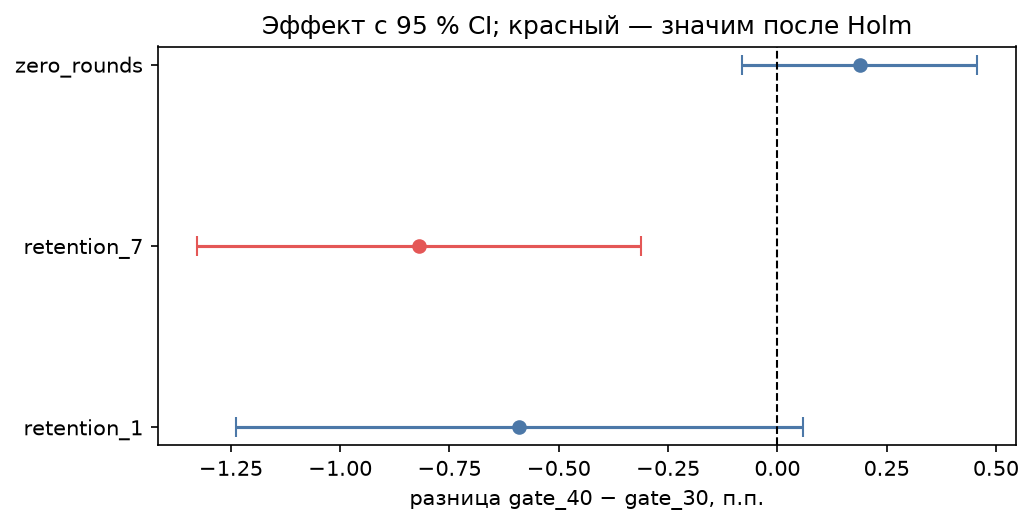

In [4]:
prop = guard[guard.metric.isin(['retention_1', 'retention_7', 'zero_rounds'])].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 3.6), dpi=150)
for i, row in prop.iterrows():
    color = '#E45756' if row.p_holm < 0.05 else '#4C78A8'
    ax.errorbar(row['diff'] * 100, i,
                xerr=[[(row['diff'] - row['ci_low']) * 100],
                      [(row['ci_high'] - row['diff']) * 100]],
                fmt='o', capsize=5, color=color)
ax.axvline(0, color='black', ls='--', lw=1)
ax.set_yticks(range(len(prop)), prop.metric)
ax.set(xlabel='разница gate_40 − gate_30, п.п.', title='Эффект с 95 % CI; красный — значим после Holm')
fig.tight_layout(); fig.savefig(FIG / '04-effect-forest.png'); plt.show()


## Guardrail: распределение раундов

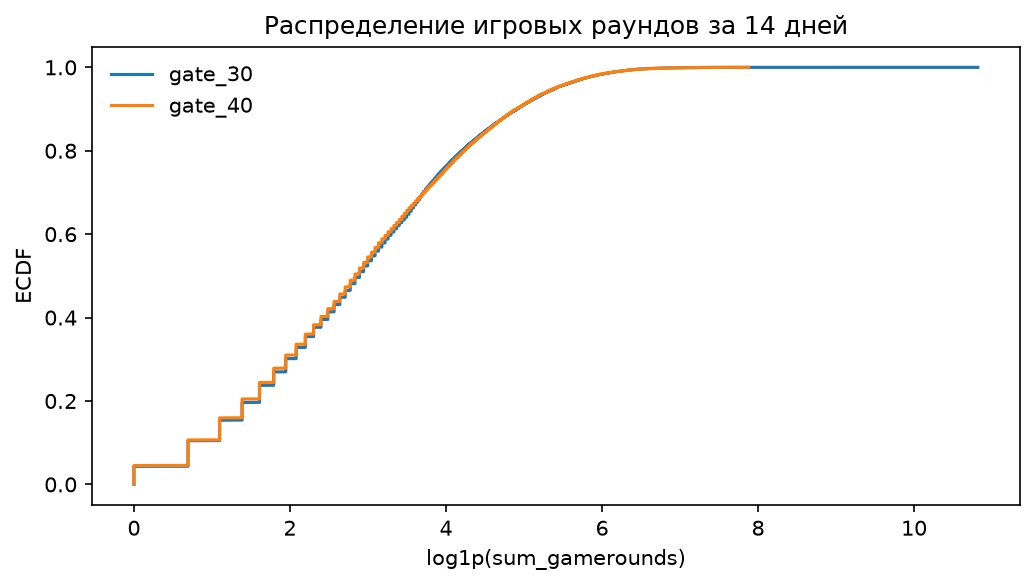

In [5]:
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
for version in ['gate_30', 'gate_40']:
    x = np.sort(df.loc[df.version == version, 'sum_gamerounds'].to_numpy())
    y = np.arange(1, len(x) + 1) / len(x)
    ax.plot(np.log1p(x), y, lw=1.5, label=version)
ax.set(xlabel='log1p(sum_gamerounds)', ylabel='ECDF',
       title='Распределение игровых раундов за 14 дней')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / '05-gamerounds-ecdf.png'); plt.show()


## Решение

- `retention_7`: −0.82 п.п. (95 % CI −1.33…−0.31), p = 0.0016, Holm p = 0.0062.
  Направление отрицательное и устойчиво к SRM: после downsampling −0.82 п.п.
  (CI −0.87…−0.78).
- `retention_1`: −0.59 п.п. (−1.24…+0.06), p = 0.074, Holm p = 0.151 — не значимо.
- Guardrails: доля нулевых раундов +0.19 п.п. (p = 0.169); медиана раундов
  17 против 16, Mann–Whitney p = 0.050, Holm p = 0.151 — значимого выигрыша нет.
- **Не раскатывать `gate_40`.** 7-дневный retention хуже, 1-дневный не лучше,
  engagement не выигрывает. Перед повторным тестом — разобраться в SRM:
  логирование, дедупликация, фактическая вероятность назначения.
- Практическая значимость: −0.82 п.п. на 1 млн установок — около 8 200
  не вернувшихся на 7-й день; денежного эффекта в данных нет, поэтому это
  retention-решение, а не финансовая оценка.

In [6]:
summary = {
    'srm_sensitivity': sens.to_dict(orient='records'),
    'guardrails': guard.to_dict(orient='records'),
    'decision': 'do_not_rollout_gate_40',
    'reason': 'retention_7 negative and Holm-significant; no guardrail gain; SRM warning',
}
(PROCESSED / 'cookie_cats_effect.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('saved', PROCESSED / 'cookie_cats_effect.json')


saved E:\Projects\Product_Analytics_Portfolio\data\processed\cookie_cats_effect.json
